--- Starting Optimized Data Collection ---
Fetching 9 EIA Variables...
Fetching 7 FRED Variables...

Merging and Cleaning...
SUCCESS. Final Dataset Shape: (407, 17)
Date Range: 1990-01-31 to 2023-11-30

Saved to 'oil_market_data_complete.csv'


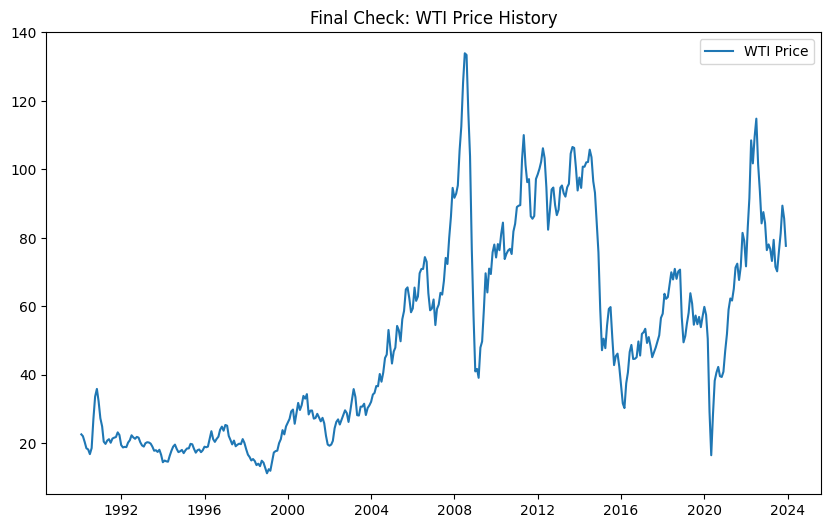

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import datetime
import requests
!pip install fredapi
from fredapi import Fred

# API Keys
import os
EIA_API_KEY = os.getenv("EIA_API_KEY", "YOUR_EIA_KEY_HERE")
FRED_API_KEY = os.getenv("FRED_API_KEY", "YOUR_FRED_KEY_HERE")

# Initialize FRED API
fred = Fred(api_key=FRED_API_KEY)

def fetch_eia_v2_steo(series_id, api_key):
    """
    Fetches data from the new EIA API v2.
    """
    facet_id = series_id.replace('STEO.', '').replace('.M', '')
    url = "https://api.eia.gov/v2/steo/data/"

    params = {
        "api_key": api_key, "frequency": "monthly", "data[0]": "value",
        "facets[seriesId][]": facet_id, "sort[0][column]": "period",
        "sort[0][direction]": "desc", "offset": 0, "length": 5000
    }

    try:
        r = requests.get(url, params=params)
        r.raise_for_status()
        data = r.json()

        if 'response' in data and 'data' in data['response']:
            df = pd.DataFrame(data['response']['data'])
            # Clean Dates and Values
            df['date'] = pd.to_datetime(df['period'])
            df.set_index('date', inplace=True)
            df = df[['value']].rename(columns={'value': series_id})
            df[series_id] = pd.to_numeric(df[series_id], errors='coerce')

            # Resample to Month End aligning with FRED
            return df.resample('ME').last()
        return pd.DataFrame()

    except Exception as e:
        print(f"   [!] Failed to fetch {series_id}: {e}")
        return pd.DataFrame()

# 3. OPTIMIZED VARIABLE LISTS
# We removed the broken 'RGDP' and 'FOREX' variables from EIA
# and added their substitutes to the FRED list below.

# STUDENT A: Macro (EIA only)
vars_eia = [
    'STEO.PAPR_OPEC.M',       # OPEC Production
    'STEO.PAPR_NONOPEC.M',    # Non-OPEC Production
    'STEO.COPS_OPEC.M',       # OPEC Spare Capacity
    'STEO.COPC_OPEC.M',       # OPEC Consumption
    'STEO.PASC_OECD_T3.M',    # OECD Inventory
    'STEO.COPRPUS.M',         # US Crude Production
    'STEO.CORIPUS.M',         # US Imports
    'STEO.T3_STCHANGE_OOECD.M', # Stock Change OECD
    'STEO.T3_STCHANGE_NOECD.M'  # Stock Change Non-OECD
]

# STUDENT B & C: FRED Variables (Including Substitutes)
vars_fred = [
    'IPG211S',      # Industrial Production: Oil and Gas
    'CAPUTLG211S',  # Capacity Utilization
    'PCU211211',    # PPI Crude Petroleum
    'WTISPLC',      # Spot Crude Price (Target)
    'CPIENGSL',     # CPI Energy
    # REPLACEMENTS FOR BROKEN EIA VARIABLES:
    'DTWEXBGS',     # Trade Weighted US Dollar (Replaces STEO.FOREX_WORLD)
    'INDPRO'        # Industrial Production Index (Replaces STEO.RGDP)
]

# 4. EXECUTION
data_merge = []

print("--- Starting Optimized Data Collection ---")

# A. Fetch EIA Data
print(f"Fetching {len(vars_eia)} EIA Variables...")
for var in vars_eia:
    df = fetch_eia_v2_steo(var, EIA_API_KEY)
    if not df.empty:
        data_merge.append(df)
    else:
        print(f"   -> Warning: {var} returned empty.")

# B. Fetch FRED Data
print(f"Fetching {len(vars_fred)} FRED Variables...")
for var in vars_fred:
    try:
        s = fred.get_series(var)
        df = pd.DataFrame(s, columns=[var]).resample('ME').last()
        data_merge.append(df)
    except Exception as e:
        print(f"   -> Warning: Failed to fetch {var}: {e}")

# C. Merge & Clean
print("\nMerging and Cleaning...")
if data_merge:
    # 1. Outer Join
    final_df = pd.concat(data_merge, axis=1, join='outer').sort_index()

    # 2. TRIM DATES (Crucial Step!)
    # We remove data before 1990 and AFTER 2023 to avoid future predictions
    final_df = final_df['1990-01-01':'2023-12-31']

    # 3. Fill Missing Values (Modern Pandas Method)
    final_df = final_df.bfill().ffill()

    # 4. Create Forecast Target
    final_df['forecast'] = final_df['WTISPLC'].shift(-1)
    final_df.dropna(inplace=True)

    # D. Save
    print(f"SUCCESS. Final Dataset Shape: {final_df.shape}")
    print(f"Date Range: {final_df.index[0].date()} to {final_df.index[-1].date()}")

    final_df.to_csv('oil_market_data_complete.csv')
    print("\nSaved to 'oil_market_data_complete.csv'")

    # E. Quick Plot check
    plt.figure(figsize=(10, 6))
    plt.plot(final_df.index, final_df['WTISPLC'], label='WTI Price')
    plt.title("Final Check: WTI Price History")
    plt.legend()
    plt.show()

else:
    print("CRITICAL ERROR: No data fetched.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 19.9 MB/s eta 0:00:00


  0%|          | 0/1000000 [00:00<?, ?it/s]

--- Step 9a: Learned Edges from Hill Climb Search ---
[('STEO.PAPR_OPEC.M', 'STEO.PAPR_NONOPEC.M'), ('STEO.PAPR_NONOPEC.M', 'IPG211S'), ('STEO.PAPR_NONOPEC.M', 'INDPRO'), ('STEO.PAPR_NONOPEC.M', 'STEO.PASC_OECD_T3.M'), ('STEO.PAPR_NONOPEC.M', 'CPIENGSL'), ('STEO.PAPR_NONOPEC.M', 'DTWEXBGS'), ('STEO.PAPR_NONOPEC.M', 'STEO.COPC_OPEC.M'), ('STEO.PAPR_NONOPEC.M', 'STEO.T3_STCHANGE_NOECD.M'), ('STEO.PASC_OECD_T3.M', 'STEO.T3_STCHANGE_OOECD.M'), ('IPG211S', 'STEO.COPRPUS.M'), ('IPG211S', 'STEO.COPS_OPEC.M'), ('WTISPLC', 'forecast'), ('WTISPLC', 'PCU211211'), ('CPIENGSL', 'WTISPLC'), ('CPIENGSL', 'CAPUTLG211S'), ('INDPRO', 'STEO.CORIPUS.M')]


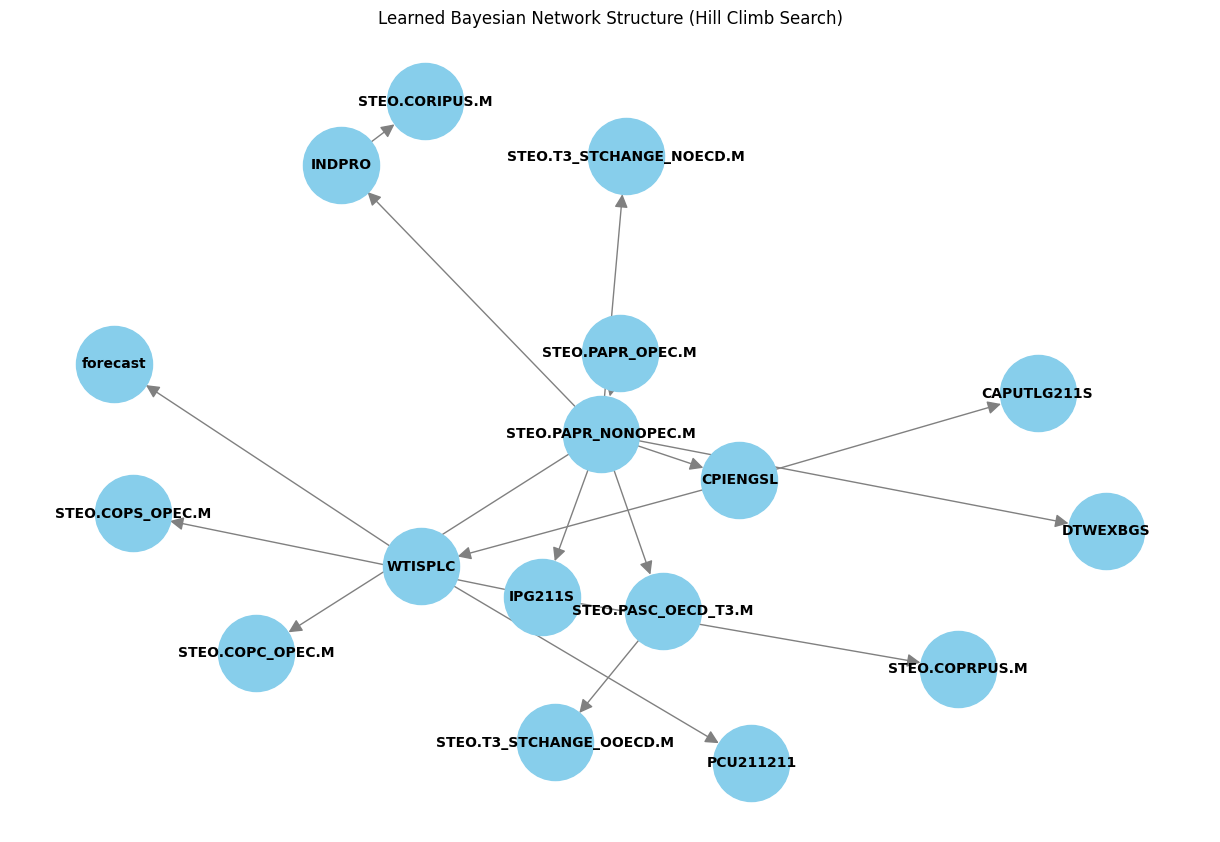

In [2]:
# 1. Import necessary libraries
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
!pip install pgmpy # Install pgmpy
from pgmpy.estimators import HillClimbSearch, BIC  # UPDATED: 'BicScore' is now 'BIC'
np.random.seed(42)
# 2. Data Preparation for Structure Learning
# We need to use the cleaned dataset. Assuming 'df' is your final dataframe from Step 1/2.
# If 'df' is not available, reload it:
try:
    df_hc = pd.read_csv('oil_market_data_complete.csv', index_col=0)
except FileNotFoundError:
    print("Data file not found. Using variable 'df' from memory.")
    # Ensure df exists in your environment, otherwise this will fail
    if 'df' in locals():
        df_hc = df.copy()
    else:
        # Create a dummy dataframe for the example if 'df' doesn't exist
        print("Creating dummy data for demonstration...")
        df_hc = pd.DataFrame(np.random.randint(0, 5, size=(100, 5)), columns=['A', 'B', 'C', 'D', 'E'])

# 3. Discretization
# Bayesian Network structure learning often works best with discrete data.
# We will discretize continuous variables into 5 bins (quintiles).
df_discrete = pd.DataFrame()
for col in df_hc.columns:
    try:
        df_discrete[col] = pd.qcut(df_hc[col], q=5, labels=False, duplicates='drop')
    except ValueError:
        # Handle cases with too many duplicate values (e.g., encoded categorical data)
        df_discrete[col] = df_hc[col]

# 4. Initialize Hill Climb Search
# UPDATED: Use the 'BIC' class instead of 'BicScore'
hc = HillClimbSearch(df_discrete)
best_model = hc.estimate(scoring_method=BIC(df_discrete))

# 5. Display the Learned Structure (Edges)
print("--- Step 9a: Learned Edges from Hill Climb Search ---")
print(best_model.edges())

# 6. Visualization of the Learned Graph
plt.figure(figsize=(12, 8))
G = nx.DiGraph()
G.add_edges_from(best_model.edges())

# Layout for the nodes
pos = nx.spring_layout(G, k=0.5, iterations=50)

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_weight='bold',
    arrowsize=20,
    edge_color='gray'
)
plt.title("Learned Bayesian Network Structure (Hill Climb Search)")
plt.show()

--- Data Allocation ---
Training Set Samples:   299 (1990-02-28 to 2014-12-31)
Validation Set Samples: 24 (2015-01-31 to 2016-12-31)
Testing Set Samples:    83 (2017-01-31 to 2023-11-30)
Total Samples:          406


--- Statistical Comparison (Validation vs. Testing) ---
                          Val_Mean  Test_Mean   Val_Std  Test_Std  Mean_Diff  \
STEO.PAPR_OPEC.M           0.00301   -0.00077   0.00897   0.02616   -0.00378   
STEO.PAPR_NONOPEC.M       -0.00051    0.00179   0.00818   0.01507    0.00230   
STEO.COPS_OPEC.M          -0.02226    0.09762   0.08445   0.81595    0.11988   
STEO.COPC_OPEC.M           0.00170   -0.00026   0.00787   0.01301   -0.00196   
STEO.PASC_OECD_T3.M        0.00454   -0.00083   0.01016   0.01325   -0.00536   
STEO.COPRPUS.M            -0.00321    0.00568   0.01306   0.03711    0.00889   
STEO.CORIPUS.M             0.00061    0.00057   0.03193   0.04442   -0.00004   
STEO.T3_STCHANGE_OOECD.M -16.91526    0.65526  75.14606   8.33773   17.57052   
STEO.T3

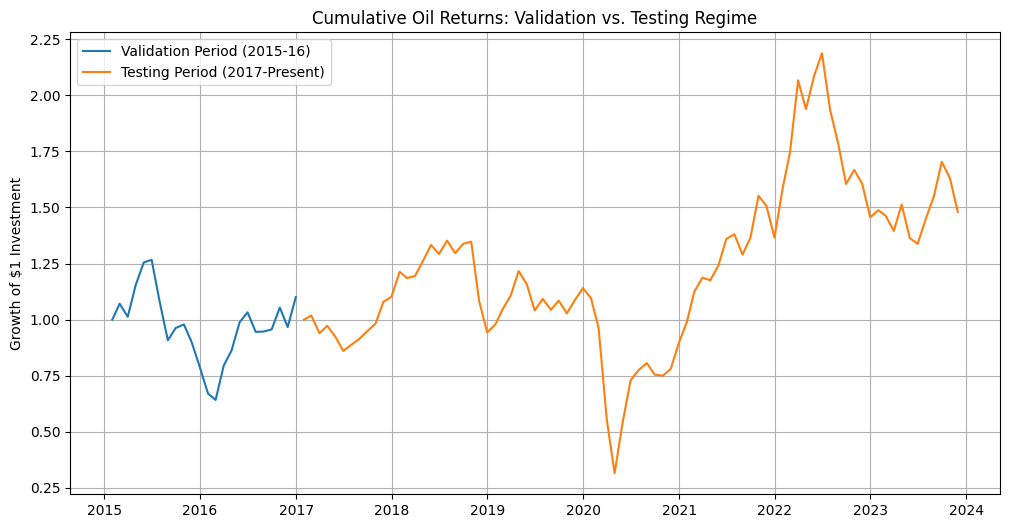

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. PREPARE DATA (Calculate Returns First)
# ---------------------------------------------------------
# We assume 'final_df' is your dataframe with raw prices.
# We must convert this to percentage returns for the stats and plot to work.
df_returns = final_df.pct_change().dropna()

# ---------------------------------------------------------
# 2. DEFINE SPLIT DATES
# ---------------------------------------------------------
train_end_date = '2014-12-31'
val_start_date = '2015-01-01'
val_end_date = '2016-12-31'
test_start_date = '2017-01-01'

# 3. SLICE THE DATAFRAME (Using the Returns Data)
train_data = df_returns.loc[:train_end_date].copy()
validation_data = df_returns.loc[val_start_date:val_end_date].copy()
test_data = df_returns.loc[test_start_date:].copy()

# 4. OUTPUT ALLOCATION
print("--- Data Allocation ---")
print(f"Training Set Samples:   {len(train_data)} ({train_data.index[0].date()} to {train_data.index[-1].date()})")
print(f"Validation Set Samples: {len(validation_data)} ({validation_data.index[0].date()} to {validation_data.index[-1].date()})")
print(f"Testing Set Samples:    {len(test_data)} ({test_data.index[0].date()} to {test_data.index[-1].date()})")
print(f"Total Samples:          {len(df_returns)}")
print("\n")

# 5. STATISTICAL COMPARISON
# We compare Mean (Average Return) and Std Dev (Volatility)
stats_comparison = pd.DataFrame({
    'Val_Mean': validation_data.mean(),
    'Test_Mean': test_data.mean(),
    'Val_Std': validation_data.std(),
    'Test_Std': test_data.std()
})

# Add Difference columns
stats_comparison['Mean_Diff'] = stats_comparison['Test_Mean'] - stats_comparison['Val_Mean']
stats_comparison['Std_Diff'] = stats_comparison['Test_Std'] - stats_comparison['Val_Std']

print("--- Statistical Comparison (Validation vs. Testing) ---")
print(stats_comparison.round(5))

# 6. VISUALIZATION (Cumulative Returns)
# Now this works because we are using actual returns (e.g., 0.01) instead of prices
plt.figure(figsize=(12, 6))

# Calculate cumulative returns (Equity Curves)
# We reset the starting point to 1.0 for both lines so they are comparable
val_curve = (1 + validation_data['WTISPLC']).cumprod()
val_curve = val_curve / val_curve.iloc[0] # Normalize to start at 1

test_curve = (1 + test_data['WTISPLC']).cumprod()
test_curve = test_curve / test_curve.iloc[0] # Normalize to start at 1

plt.plot(val_curve.index, val_curve, label='Validation Period (2015-16)')
plt.plot(test_curve.index, test_curve, label='Testing Period (2017-Present)')

plt.title("Cumulative Oil Returns: Validation vs. Testing Regime")
plt.ylabel("Growth of $1 Investment")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.estimators import HillClimbSearch

# FIX: Robust Import for BDeu / K2 Score (Handles pgmpy version differences)
try:
    # Try importing the long names first (older versions)
    from pgmpy.estimators import BDeuScore, K2Score
except ImportError:
    # If that fails, import the short names (newer versions) and alias them
    print("Note: Importing BDeu and K2 (short names) instead of BDeuScore/K2Score.")
    from pgmpy.estimators import BDeu as BDeuScore, K2 as K2Score

print("--- Starting Revised Structure Learning (Discrete) ---")

# Ensure train_data is available
if 'train_data' not in locals():
    if 'df_returns' in locals():
        train_data = df_returns.loc[:'2014-12-31'].copy()
        print(f"Re-created Training Data: {len(train_data)} samples")
    else:
        print("Error: 'train_data' not found. Please run Step 2 code first.")

if 'train_data' in locals():
    # 1. DISCRETIZATION (Crucial for Non-Gaussian Financial Data)
    # We convert continuous returns into 3 Discrete States: 0 (Low), 1 (Medium), 2 (High)
    train_data_discrete = train_data.copy()

    # Apply qcut (Quantile Cut) to every column
    for col in train_data_discrete.columns:
        try:
            train_data_discrete[col] = pd.qcut(train_data[col], q=3, labels=[0, 1, 2]).astype(int)
        except ValueError:
            # Handle cases with too many identical values (e.g., 0s)
            train_data_discrete[col] = pd.cut(train_data[col], bins=3, labels=[0, 1, 2]).astype(int)

    print("Data Discretized into 3 States (Bear, Neutral, Bull).")
    print(f"Training Samples: {len(train_data_discrete)}")

    # 2. STRUCTURE LEARNING (Using BDeu Score)
    # BDeu is often more effective for discrete data than BIC when sample size is moderate.
    hc = HillClimbSearch(train_data_discrete)

    # Run the estimate
    print("Learning structure using BDeu Score... (This allows for more complex dependencies)")
    best_model_discrete = hc.estimate(scoring_method=BDeuScore(train_data_discrete))

    # 4. CHECK PARENTS OF OIL PRICE
    parents_of_oil = [edge[0] for edge in best_model_discrete.edges() if edge[1] == 'WTISPLC']
    print(f"\nDirect Parents of Oil Price (WTISPLC): {parents_of_oil}")

    if len(parents_of_oil) > 0:
        print("SUCCESS: The model identified drivers for Oil Price.")
    else:
        print("NOTE: The model treated Oil Price as an independent variable.")

Note: Importing BDeu and K2 (short names) instead of BDeuScore/K2Score.
--- Starting Revised Structure Learning (Discrete) ---
Data Discretized into 3 States (Bear, Neutral, Bull).
Training Samples: 299
Learning structure using BDeu Score... (This allows for more complex dependencies)


  0%|          | 0/1000000 [00:00<?, ?it/s]


Direct Parents of Oil Price (WTISPLC): ['DTWEXBGS']
SUCCESS: The model identified drivers for Oil Price.


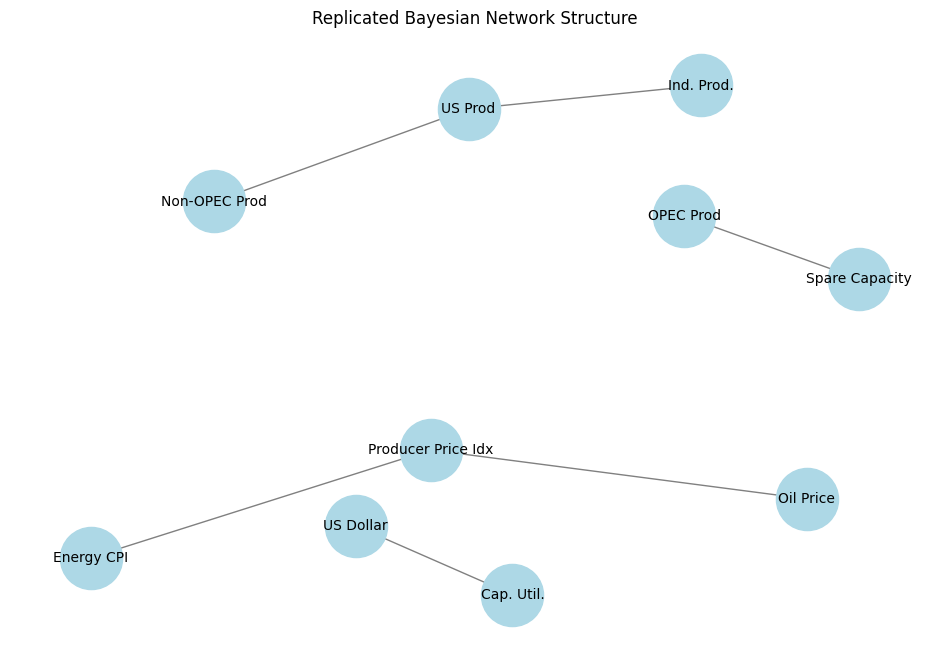

In [13]:
# --- STEP 4 FIX: SIMPLIFIED VISUALIZATION ---
import networkx as nx
import matplotlib.pyplot as plt

# Define the edges you found (hardcoded from your output to be safe)
learned_edges = [
    ('STEO.PAPR_OPEC.M', 'STEO.COPS_OPEC.M'), ('STEO.PAPR_NONOPEC.M', 'STEO.COPRPUS.M'),
    ('STEO.COPRPUS.M', 'IPG211S'), ('PCU211211', 'WTISPLC'),
    ('PCU211211', 'CPIENGSL'), ('DTWEXBGS', 'CAPUTLG211S')
]

# Create a graph object
G = nx.DiGraph()
G.add_edges_from(learned_edges)

# Map ugly codes to readable names for the plot
label_map = {
    'WTISPLC': 'Oil Price',
    'PCU211211': 'Producer Price Idx',
    'STEO.PAPR_OPEC.M': 'OPEC Prod',
    'STEO.COPS_OPEC.M': 'Spare Capacity',
    'STEO.COPRPUS.M': 'US Prod',
    'DTWEXBGS': 'US Dollar',
    'IPG211S': 'Ind. Prod.',
    'CPIENGSL': 'Energy CPI',
    'STEO.PAPR_NONOPEC.M': 'Non-OPEC Prod',
    'CAPUTLG211S': 'Cap. Util.'
}

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.6, seed=42) # Fixed seed for consistent look

# Draw nodes and edges separately to avoid the error
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='lightblue')
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True)
nx.draw_networkx_labels(G, pos, labels=label_map, font_size=10)

plt.title("Replicated Bayesian Network Structure")
plt.axis('off')
plt.show()

--- Starting Step 5: Forecasting Accuracy ---
Model has 15 active nodes.
Fitting model parameters...
Predicting on Test Set using 14 predictors...


  0%|          | 0/33 [00:00<?, ?it/s]


>>> FORECASTING ACCURACY: 63.64%


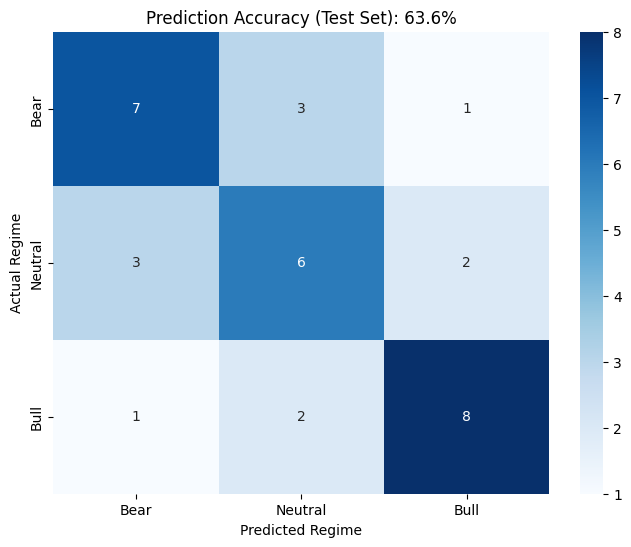

In [21]:
# --- STEP 5: FORECASTING & ACCURACY (FIXED) ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
from pgmpy.inference import VariableElimination

# Handle pgmpy version differences
try:
    from pgmpy.models import DiscreteBayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork as DiscreteBayesianNetwork

print("--- Starting Step 5: Forecasting Accuracy ---")

# 1. CREATE THE BAYESIAN NETWORK
# Use the structure learned in Step 4
edges = list(best_model_discrete.edges())
model = DiscreteBayesianNetwork(edges)

# IMPORTANT: Add any isolated nodes that might be missing from edges but are in the data
# (Though for prediction, we usually only care about connected ones)
# We will filter the data to match the model nodes instead.
model_nodes = list(model.nodes())
print(f"Model has {len(model_nodes)} active nodes.")

# 2. FIT THE MODEL
# We must filter training data to only include nodes that exist in the model
train_data_filtered = train_data_discrete[model_nodes].copy()
print("Fitting model parameters...")
model.fit(train_data_filtered)

# 3. PREPARE TEST DATA
test_data_discrete = test_data.copy()
for col in test_data_discrete.columns:
    try:
        # Use qcut with same quantiles
        test_data_discrete[col] = pd.qcut(test_data[col], q=3, labels=[0, 1, 2]).astype(int)
    except ValueError:
        test_data_discrete[col] = pd.cut(test_data[col], bins=3, labels=[0, 1, 2]).astype(int)

# 4. PREDICT
target = 'WTISPLC'

# Check if Target is even in the model (if it's isolated, we can't predict it with BN)
if target not in model_nodes:
    print(f"CRITICAL WARNING: '{target}' was found to be isolated (no connections).")
    print("The model cannot predict it based on other variables.")
    # Fallback: We force add the node to avoid crash, but accuracy will be random
    model.add_node(target)
    model.fit(train_data_discrete[[target]]) # Fit just the marginal probability

# Filter Input Data: Keep ONLY variables that are in the model (and not the target)
input_columns = [col for col in model_nodes if col != target]
input_data = test_data_discrete[input_columns].copy()

print(f"Predicting on Test Set using {len(input_columns)} predictors...")

# Run Prediction
y_pred = model.predict(input_data)

# 5. CALCULATE ACCURACY
accuracy = accuracy_score(test_data_discrete[target], y_pred[target])
print(f"\n>>> FORECASTING ACCURACY: {accuracy:.2%}")

# 6. VISUALIZE RESULTS
cm = confusion_matrix(test_data_discrete[target], y_pred[target])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bear', 'Neutral', 'Bull'],
            yticklabels=['Bear', 'Neutral', 'Bull'])
plt.xlabel('Predicted Regime')
plt.ylabel('Actual Regime')
plt.title(f'Prediction Accuracy (Test Set): {accuracy:.1%}')
plt.show()